## Info 290T: Continual Learning - Final Project

This is a simple notebook analyzing the accuracy of the outputs of our continual learning system. The base level of system is designed to take CSVs of user transactions and predict the categories of these transactions, such as "Rent" or "Groceries," as well as store embeddings of them using a module called distilbert. The continual learning portion of the model tries to track and remember these changes, but without overriding all previous categorizations to the point of catastrophic forgetting.

#### Initial Baseline (Frozen Model, distilbert categorizations only)

First, we need to calculate the accuracy of this baseline model. This will be the point to which we can make comparisons, using other versions of the model with continual learning implemented.

##### About the dataset

`data/transactions_2026.csv` is synthetic and written by `src/data_generator.py` (its docstring is the closest thing we have to a dataset card). It is one year (Jan–Dec 2026) of bank transactions for one simulated user: a 25-year-old Berkeley student who studies in coffee shops and hangs out at breweries, pays about $1,500 a month in housing (rent to the landlord plus a share to her roommate Ashley), and spends about $2,500 a month.

Columns: `txn_id`, `date`, `description` (raw bank text), `amount` (negative = money out), `note` (Venmo note, empty otherwise), and `true_category`, which is what *this user* wants the row filed as. The system never sees `true_category`; only the simulated user and the scoring read it.

**Categories.** The frozen model ([DoDataThings/distilbert-us-transaction-classifier](https://huggingface.co/DoDataThings/distilbert-us-transaction-classifier)) can output 16 labels: Education, Entertainment, Fees, Groceries, Healthcare, Housing, Income, Insurance, Personal Care, Restaurants, Shopping, Subscription, Transfer, Transportation, Travel, Utilities. The user adds three of her own that the model cannot output at all: **Social**, **Coffee**, and **Gifts**. These are built in on purpose: the only way to get them right is to learn from the user's corrections, which is exactly what the continual learning part has to do.

**Shifts built into the year:**

| Type | When | Shift |
|---|---|---|
| concept | all year | Ramen and breweries are **Social** (no such model label) |
| concept | May 9 | One $50 Trader Joe's purchase is a gift card → **Gifts**, once. Trader Joe's should stay Groceries afterwards |
| concept | Jul | Coffee shops change from Restaurants to **Coffee** |
| covariate | Sep | Rent goes from \$1,225 to \$1,300 (still Housing); a new brewery, Ale Industries, appears (still Social) |
| covariate | Oct | She switches from Chase to Bank of America: every description changes format (CHECKCARD prefixes, Zelle names written LAST FIRST, ...) |
| concept | Nov | Ashley moved out: Zelle to Ashley changes from rent share (Housing) to small payments for drinks (Social) |

January to June are treated as already reviewed; July to December are the months the system has to categorize live.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
baseline_df = pd.read_csv('results/frozen_predictions_2026.csv')
print(baseline_df.head())

   txn_id        date                                        description  \
0       1  2026-01-01             UC BERKELEY PAYROLL PPD ID: 1946000123   
1       2  2026-01-01  Zelle payment to Bayview Property Mgmt JPM99ES...   
2       3  2026-01-02           Zelle payment to Ashley Kim JPM99U2T011V   
3       4  2026-01-02                           CAFFE STRADA BERKELEY CA   
4       5  2026-01-03                              PHILZ COFFEE BERKELEY   

    amount note true_category    predicted  confidence  correct  
0  1350.00  NaN        Income       Income       1.000     True  
1 -1225.00  NaN       Housing     Transfer       0.996    False  
2  -275.00  NaN       Housing     Transfer       0.990    False  
3    -6.96  NaN   Restaurants  Restaurants       0.998     True  
4    -7.49  NaN   Restaurants  Restaurants       1.000     True  


In [3]:
# What's the overall accuracy? 

print("Overall baseline accuracy: ", round(baseline_df[baseline_df["correct"] == True].shape[0] / baseline_df.shape[0] * 100, 2), "%")

Overall baseline accuracy:  41.59 %


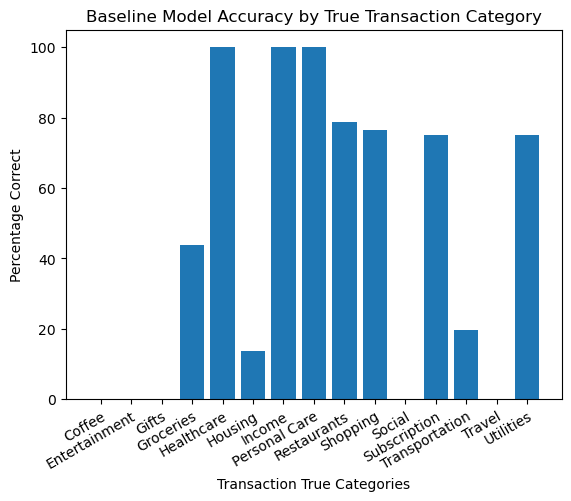

In [4]:
# What does accuracy look like per category? (based on the true assigned category)

baseline_correct = baseline_df.groupby('true_category').sum()["correct"]
baseline_grouped = baseline_correct.to_frame().reset_index()
baseline_total = baseline_df.groupby('true_category').count()["txn_id"].to_frame().reset_index()
baseline_grouped["total"] = baseline_total["txn_id"]
baseline_grouped["percentage_correct"] = round(baseline_grouped["correct"] / baseline_grouped["total"] * 100, 2)

fig, ax = plt.subplots()
ax.bar(baseline_grouped["true_category"], baseline_grouped["percentage_correct"])
plt.title("Baseline Model Accuracy by True Transaction Category")
plt.xlabel("Transaction True Categories")
ax.tick_params(axis="x", labelrotation=30)
plt.setp(ax.get_xticklabels(), ha="right", rotation_mode="anchor")
plt.ylabel("Percentage Correct")
plt.show()

In [5]:
baseline_grouped

,true_category,correct,total,percentage_correct
0,Coffee,0,105,0.00
1,Entertainment,0,15,0.00
2,Gifts,0,1,0.00
3,Groceries,25,57,43.86
4,Healthcare,6,6,100.00
5,Housing,3,22,13.64
6,Income,24,24,100.00
7,Personal Care,10,10,100.00
8,Restaurants,123,156,78.85
9,Shopping,26,34,76.47


The 0% for **Coffee**, **Social**, and **Gifts** is by design: the model has no such labels, so it can never get these rows right. Together they are 211 of 630 rows (33%), which caps the frozen model's overall accuracy at 67%. These rows are what the continual learning part has to fix.

The other weak categories (**Entertainment**, **Housing**, **Transportation**, and partly **Groceries**) *are* model labels, so missing labels don't explain them. Most of these errors go to **Transfer**, a model label the user never uses: any Zelle or Venmo payment gets filed as Transfer whatever it was for (e.g. rent paid by Zelle to the landlord). The model is also very confident on these errors (0.996 on the first rent payment), so confidence alone can't flag them.

Keep sample size in mind: Gifts and Travel have one row each and Healthcare has six, so their 0% or 100% says very little. Gifts is better treated as a single pass/fail case (after the correction, does Trader Joe's stay Groceries?).

Also note that before July, coffee shops are labelled Restaurants, and the model gets those right, which lifts the Restaurants accuracy.

The goal for the continual learning version: raise accuracy on these categories without lowering it on the ones the model already gets right.

##### Separating the two kinds of error

Because a third of the rows use categories the model doesn't have, the overall 41.6% mixes two different problems. Splitting the rows by whether their true category is one of the model's labels separates them.

In [ ]:
# Split accuracy: categories the model can output vs. the user's own (Social, Coffee, Gifts)

# The frozen model's 16 labels (its config.id2label; see src/frozen_base.py)
MODEL_CATEGORIES = {
    "Education", "Entertainment", "Fees", "Groceries", "Healthcare", "Housing", "Income", "Insurance",
    "Personal Care", "Restaurants", "Shopping", "Subscription", "Transfer", "Transportation", "Travel", "Utilities",
}

baseline_df["in_model"] = baseline_df["true_category"].isin(MODEL_CATEGORIES)

split = baseline_df.groupby("in_model")["correct"].agg(correct="sum", total="size")
split["percentage_correct"] = round(split["correct"] / split["total"] * 100, 2)
split.index = split.index.map({True: "Model's categories", False: "User's own (Social, Coffee, Gifts)"})
split

On the rows whose category the model has, the frozen model gets 62.5% right; on the user's own categories it gets 0% by construction. Reporting both numbers keeps the two problems apart when we compare against the continual learning versions.

Next, accuracy by month shows where the shifts in the dataset hit.

In [ ]:
# Accuracy by month, with the built-in shifts marked

baseline_df["month"] = pd.to_datetime(baseline_df["date"]).dt.month

monthly = pd.DataFrame({
    "all_rows": baseline_df.groupby("month")["correct"].mean() * 100,
    "model_categories_only": baseline_df[baseline_df["in_model"]].groupby("month")["correct"].mean() * 100,
    "rows": baseline_df.groupby("month").size(),
}).round(1)

SHIFTS = {5: "Gift card", 7: "Coffee split", 9: "Rent up, new brewery", 10: "Bank switch", 11: "Ashley moves out"}

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(monthly.index, monthly["all_rows"], marker="o", label="All rows")
ax.plot(monthly.index, monthly["model_categories_only"], marker="o", label="Model's categories only")
for m, label in SHIFTS.items():
    ax.axvline(m, color="grey", linestyle=":", linewidth=1)
    ax.text(m + 0.05, 101, label, rotation=30, fontsize=8, ha="left", va="bottom")
ax.axvspan(0.5, 6.5, color="grey", alpha=0.08, label="Reviewed (Jan–Jun)")
ax.set_xticks(range(1, 13))
ax.set_xlim(0.5, 12.5)
ax.set_ylim(0, 100)
ax.set_xlabel("Month (2026)")
ax.set_ylabel("Percentage Correct")
ax.set_title("Baseline Model Accuracy by Month", pad=45)
ax.legend(loc="lower left", fontsize=8)
plt.show()

monthly

Accuracy on the model's own categories is stable at roughly 75–90% from January to June, then falls in three steps that line up with the built-in shifts:

- **July (Coffee split):** overall accuracy drops from 66% to 37%, because coffee shops become Coffee. The model's-categories line drops too (78% → 58%), mostly because the easy coffee-shop rows that used to count as correct Restaurants have left that group.
- **September:** a partial recovery; the rent increase and the new brewery don't hurt the frozen model much on their own.
- **October (bank switch):** accuracy collapses to about 5–6% and stays there. After the switch, 144 of the 173 October–December rows are predicted as Transfer. This is a covariate shift (same meaning, new text format), and it hurts far more than any of the new categories.

So the memory has two different jobs: learn the user's own categories (concept shift), and keep working when the description format changes (covariate shift). The second one cannot be solved by storing corrections alone, which is why a text-normalization step is planned.